#**SPRINT 9**

In [1]:
%pip install pandas numpy matplotlib seaborn sqlalchemy pymysql

DEPRECATION: Configuring installation scheme with distutils config files is deprecated and will no longer work in the near future. If you are using a Homebrew or Linuxbrew Python, please see discussion at https://github.com/Homebrew/homebrew-core/issues/76621
Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/usr/local/opt/python@3.9/bin/python3.9 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Librerías para análisis de datos
import pandas as pd
import numpy as np

# Librerías para visualización de datos
import matplotlib.pyplot as plt
import seaborn as sns
import squarify

In [3]:
# Formato para todos los gráficos
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

`sns.set_theme()`: Configura el diseño y los colores generales de **Seaborn**

`style="whitegrid"`: Establece un fondo blanco con una cuadrícula de líneas grises muy suaves.

`palette="muted"`: Aplica una paleta de colores apagada/suave en lugar de los colores primarios por defecto.

---

`plt.rcParams`: Modifica los parámetros internos del **Matplotlib**

`["figure.figsize"] = (10, 5)`: Define el tamaño por defecto de todos los lienzos o figuras en 10 de ancho por 5 de alto.

`["font.size"] = 11`: Establece el tamaño base de la letra en 11 puntos para todos los textos del gráfico (títulos, etiquetas de los ejes y valores numéricos).


In [4]:
# Formato números decimales en las tablas
pd.options.display.float_format = '{:.2f}'.format

#**NIVEL 1**
##**Ejercicio 1**
---
El análisis tiene como objetivo conocer mejor el comportamiento de las transacciones y obtener información útil sobre la actividad de ventas. Para ello, se estudiarán los datos disponibles y se analizarán cuatro aspectos principales:

- **A. Evolución de las transacciones:** cómo ha variado el número de transacciones a lo largo del tiempo.

- **B. Volumen de facturación por usuario:** qué usuarios generan un mayor volumen de facturación.

- **C. Importe de las transacciones:** si existen diferencias en los importes según la hora del día y según las operaciones hayan sido aceptadas o rechazadas.

- **D. Actividad según el día de la semana:** qué días concentran un mayor número de ventas.

Los resultados se representarán mediante visualizaciones realizadas con Python, seleccionando en cada caso el tipo de gráfico más adecuado para facilitar su interpretación. Además, se compararán las visualizaciones iniciales con propuestas alternativas generadas mediante herramientas de IA para valorar cuál representa mejor la información obtenida.

---

###**A. Evolución de las transacciones**

In [5]:
# Cargar el archivo
ruta = "/Users/mar/Downloads/N1-Ex.8__transactions.csv"
transactions =  pd.read_csv(ruta, sep = ";")

# Conversión de la columna temporal
transactions['timestamp'] = pd.to_datetime(transactions['timestamp'])

# Comprobar que se ha cargado bien
transactions.sample()

,id,card_id,business_id,timestamp,amount,declined,product_ids,user_id,lat,longitude,discount_amount,tax_amount,shipping_amount,channel,campaign_id,device_type,is_international,decline_reason,distance_km
48486,48EDEF1A-B532-4102-B228-28402DC10CCE,CcS-5339,b-2358,2015-05-20 12:23:23,295.98,1,"81, 46, 89",758,41.88,12.78,4.82,53.37,0.00,store,NO_CAMPAIGN,pos,0,limit_exceeded,17.90


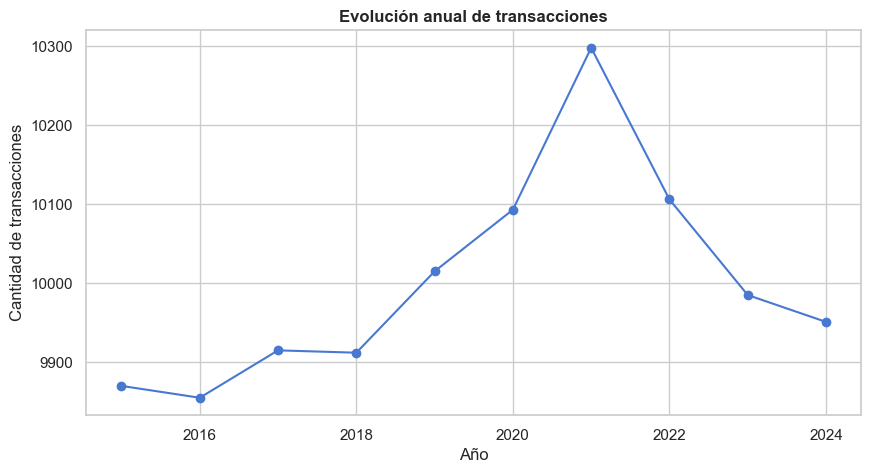

In [6]:
# Calcular nº de transacciones a lo largo del tiempo
transactions_year = transactions.groupby(transactions['timestamp'].dt.year).agg({'id':'count'}).reset_index()

# Gráfico de líneas
transactions_year.plot(x='timestamp', y='id', kind='line', marker='o', legend=False)

# Títulos y etiquetas
plt.title("Evolución anual de transacciones", weight='bold')
plt.xlabel("Año")
plt.ylabel("Cantidad de transacciones")

# Mostrar gráfico
plt.show()

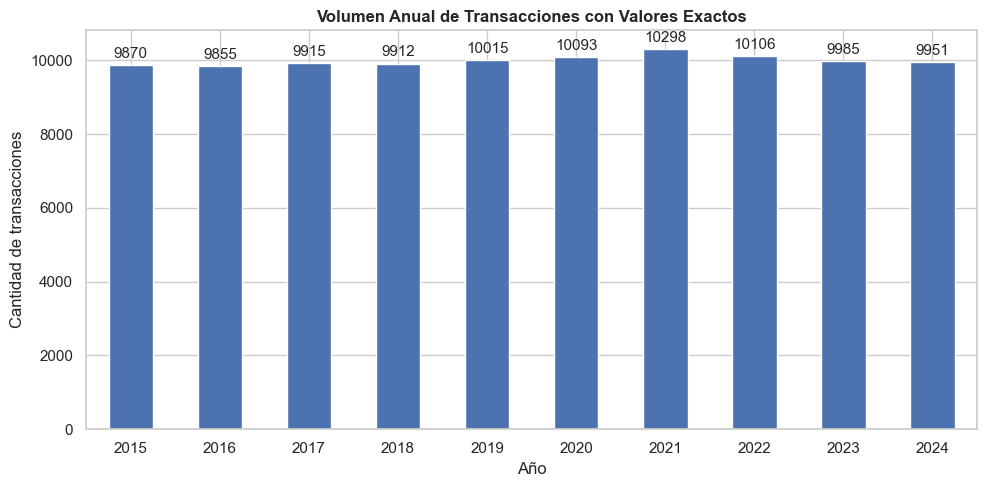

In [7]:
# Propuesta IA: Gráfico de barras con etiquetas

ax = transactions_year.plot(
    x='timestamp',
    y='id',
    kind='bar',
    color='#4c72b0',
    legend=False
)

plt.title("Volumen Anual de Transacciones con Valores Exactos", weight='bold')
plt.xlabel("Año")
plt.ylabel("Cantidad de transacciones")
plt.xticks(rotation=0)

# Añadir el número exacto encima de cada barra
plt.bar_label(ax.containers[0], padding=3)

plt.tight_layout()
plt.show()



In [8]:
# 1. Encontrar el año con más transacciones (pico)
max_tx = transactions_year.loc[transactions_year['id'].idxmax()]
peak_year = int(max_tx['timestamp'])
peak_val = max_tx['id']

# 2. Obtener el valor del último año (2024)
last_row = transactions_year.iloc[-1]
last_year = int(last_row['timestamp'])
last_val = last_row['id']

# 3. Calcular la variación porcentual desde el pico
var_pct = ((last_val - peak_val) / peak_val) * 100

print(f"Año pico: {peak_year} con {peak_val:,} transacciones")
print(f"Último año ({last_year}): {last_val:,} transacciones")
print(f"Variación desde el pico: {var_pct:.2f}%")

Año pico: 2021 con 10,298 transacciones
Último año (2024): 9,951 transacciones
Variación desde el pico: -3.37%


**1. Qué vemos en el gráfico y qué significa para el negocio**

Las ventas crecen año tras año hasta tocar techo en 2021. Desde ahí bajan un 3,37% hasta 2024. No es una caída alarmante, pero sí una señal clara de estancamiento: la empresa ha dejado de crecer y toca revisar si estamos perdiendo clientes o si el ticket medio compensa esta bajada de compras.

**2. Alternativa de la IA**

Propone representarlo con un gráfico de barras por año.

**3. Valoración crítica (Líneas vs. Barras)**

La propuesta de la IA me parece un paso atrás. Como las barras tienen que empezar en 0 y manejamos cifras cercanas a 10.000 operaciones, las columnas se ven prácticamente iguales y esa bajada del 3% se vuelve invisible. El gráfico de líneas es mucho más honesto y útil aquí porque muestra la dirección de la tendencia a simple vista.

###**B. Volumen de facturación por usuario**

In [9]:
# 1. Regla de negocio: considerar solo transacciones aceptadas
valid_transaction = transactions[transactions['declined'] == 0]

# 2. Agrupar por usuario, sumar el importe (amount) y ordenar de mayor a menor
top15_users = (
    valid_transaction.groupby('user_id')['amount']
    .sum()
    .sort_values(ascending=False)
    .head(15)
    .reset_index()
)

# ID debe ser texto no número
top15_users['user_id'] = top15_users['user_id'].astype(str) #no es neceario

# Mostramos los primeros resultados para verificar
top15_users.head()

,user_id,amount
0,289,47332.90
1,318,46393.44
2,455,40594.55
3,417,37393.91
4,185,34560.87


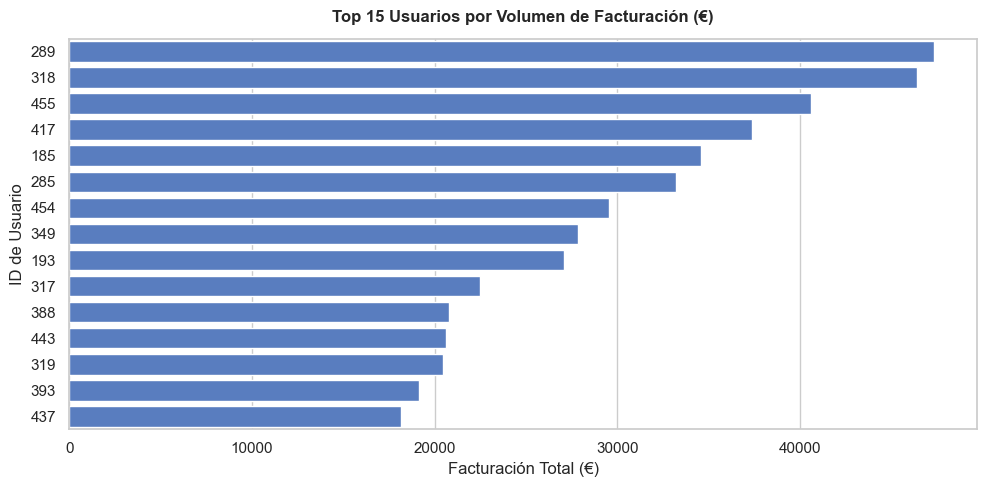

In [10]:
# Gráfico de barras horizontal con Seaborn
sns.barplot(
    data=top15_users,
    x='amount',
    y='user_id',
    order=top15_users['user_id']
)

# Título y etiquetas
plt.title("Top 15 Usuarios por Volumen de Facturación (€)", weight='bold', pad=12)
plt.xlabel("Facturación Total (€)")
plt.ylabel("ID de Usuario")
plt.tight_layout()

# Mostrar gráfico
plt.show()

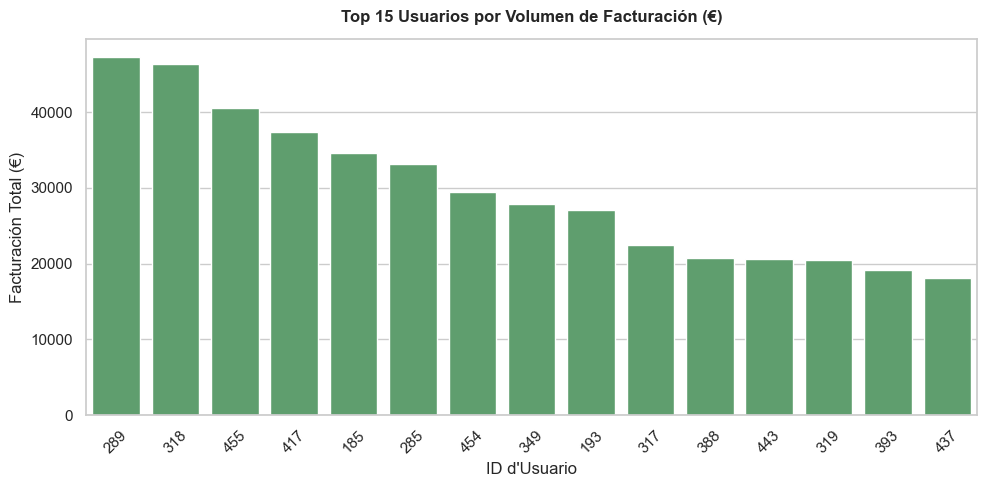

In [11]:
# Prouesta IA: Barras verticales y rotación de etiquetas
sns.barplot(
    data=top15_users,
    x='user_id',
    y='amount',
    color='#55a868'
)

plt.title("Top 15 Usuarios por Volumen de Facturación (€)", weight='bold', pad=12)
plt.xlabel("ID d'Usuario")
plt.ylabel("Facturación Total (€)")
plt.xticks(rotation=45)  # Rotación necesaria para que los IDs no se superpongan
plt.tight_layout()
plt.show()

In [12]:
total_facturado = valid_transaction['amount'].sum()
top15_facturado = top15_users['amount'].sum()
pct_concentracion = (top15_facturado / total_facturado) * 100

print(f"Facturación total plataforma: {total_facturado:,.2f} €")
print(f"Facturación Top 15 usuarios:  {top15_facturado:,.2f} €")
print(f"Porcentaje de concentración:  {pct_concentracion:.2f}%")

Facturación total plataforma: 29,025,382.41 €
Facturación Top 15 usuarios:  445,567.49 €
Porcentaje de concentración:  1.54%


**1. Qué vemos en el gráfico y qué significa para el negocio**

Los 15 clientes que más compran solo suponen el 1,54% del dinero total que entra. Esto significa que la empresa no depende de clientes VIP para sobrevivir, sino de miles de compradores pequeños. Si se va cualquiera de ellos no pasa nada, porque el negocio está muy repartido.

**2. Alternativa de la IA**

Propone representarlo con un gráfico de barras horizontal con las etiquetas giradas 45º para una mejor lectura.

**3. Valoración crítica (B.Horizontales vs. B.Verticales)**

La propuesta de la IA al usar un formato vertical con 15 categorías, los identificadores de usuario chocan entre sí en el eje horizontal y obligan a rotar el texto 45 grados, lo que dificulta una lectura cómoda. El gráfico inicial de barras horizontales permite leer cada ID de forma natural de izquierda a derecha y presenta el ranking ordenado de arriba a abajo como una lista limpia.

###**C. Importe de las transacciones**

In [13]:
# 1. Se la hora del día (de 0 a 23)
transactions['hour'] = transactions['timestamp'].dt.hour

# 2. Se convierte el 0 y 1 de declined en palabras: Aceptada y Rechazada
transactions['status'] = transactions['declined'].map({0: 'Aceptada', 1: 'Rechazada'})

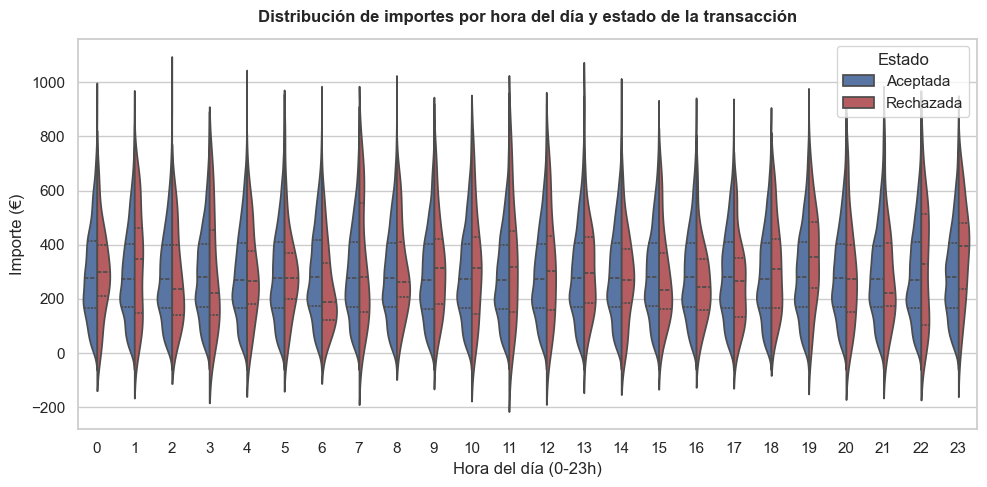

In [14]:
# Gráfico de violín con Seaborn
sns.violinplot(
    data=transactions,
    x='hour',
    y='amount',
    hue='status',
    split=True,            # Junta aceptadas y rechazadas en un solo violín partido a la mitad
    inner='quartile',      # Muestra las líneas de la mediana y los cuartiles dentro
    palette={'Aceptada': '#4c72b0', 'Rechazada': '#c44e52'}
)

# Título y etiquetas
plt.title("Distribución de importes por hora del día y estado de la transacción", weight='bold', pad=12)
plt.xlabel("Hora del día (0-23h)")
plt.ylabel("Importe (€)")
plt.legend(title="Estado", loc='upper right')
plt.tight_layout()

# Mostrar gráfico
plt.show()

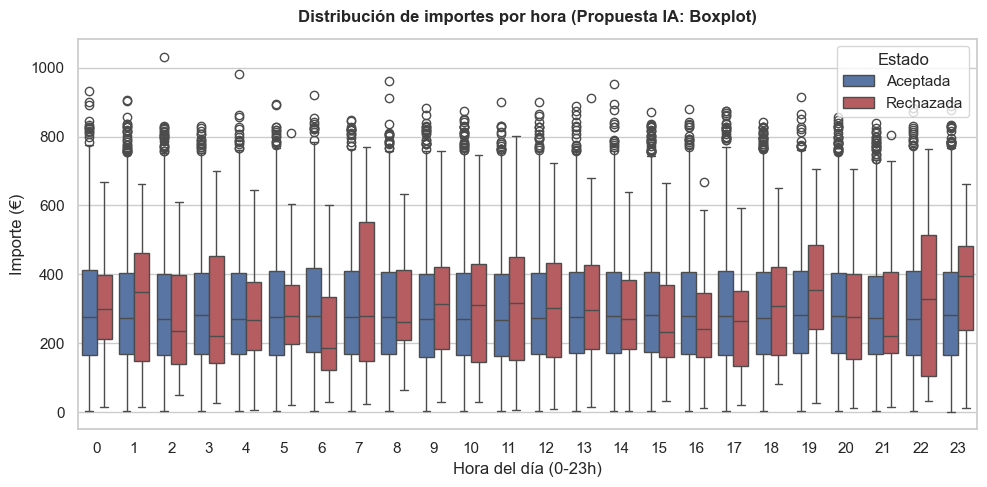

In [15]:
# Gráfico alternativo propuesto por la IA: Boxplot por hora y estado

sns.boxplot(
    data=transactions,
    x='hour',
    y='amount',
    hue='status',
    palette={'Aceptada': '#4c72b0', 'Rechazada': '#c44e52'}
)

plt.title("Distribución de importes por hora (Propuesta IA: Boxplot)", weight='bold', pad=12)
plt.xlabel("Hora del día (0-23h)")
plt.ylabel("Importe (€)")
plt.legend(title="Estado", loc='upper right')
plt.tight_layout()
plt.show()

In [16]:
# Calculo medias y medianas reales
stats_status = transactions.groupby('status')['amount'].agg(['mean', 'median', 'count'])
print(stats_status)

# Diferencia porcentual entre el importe medio rechazado y aceptado
media_ok = stats_status.loc['Aceptada', 'mean']
media_ko = stats_status.loc['Rechazada', 'mean']
diff_pct = ((media_ko - media_ok) / media_ok) * 100

print(f"\nImporte medio aceptadas: {media_ok:.2f} €")
print(f"Importe medio rechazadas: {media_ko:.2f} €")
print(f"Diferencia: Las rechazadas son un {diff_pct:.2f}% respecto a las aceptadas.")

            mean  median  count
status                         
Aceptada  292.85  275.88  99112
Rechazada 304.16  287.22    888

Importe medio aceptadas: 292.85 €
Importe medio rechazadas: 304.16 €
Diferencia: Las rechazadas son un 3.86% respecto a las aceptadas.


**1. Qué vemos en el gráfico y qué significa para el negocio**

El comportamiento de gasto es muy estable a lo largo de todo el día: los clientes compran importes similares a cualquier hora. Además, las compras rechazadas representan menos del 1% del total (888 operaciones frente a 99.112 aceptadas) y su importe medio (304,16 €) apenas supera en un 3,86% al de las aceptadas (292,85 €). Esto indica que los rechazos no se deben a compras de importes desorbitados ni a fraude masivo, sino a incidencias habituales de pago.

**2. Alternativa de la IA**

La IA propone un boxplot (gráfico de cajas) en lugar del violín

**3. Valoración crítica (Violín vs. Boxplot)**

En este caso, la propuesta de la IA (el boxplot) es bastante razonable, pero el violinplot aporta más valor: su silueta enseña dónde se acumulan realmente las compras dentro de cada franja horaria. Además, al partir el violín por la mitad (split=True), permite comparar en una sola figura la forma de las aceptadas y rechazadas sin saturar la visualización.

###**D. Actividad según el día de la semana**

In [17]:
# 1. Se Filtran las ventas válidas (no rechazadas)
ventas = transactions[transactions['declined'] == 0].copy()

# 2. Se sacan directamente el día de la semana
ventas['dia_semana'] = ventas['timestamp'].dt.day_name()

# 3. Se define el orden lógico de la semana (Lunes a Domingo)
dias_orden = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

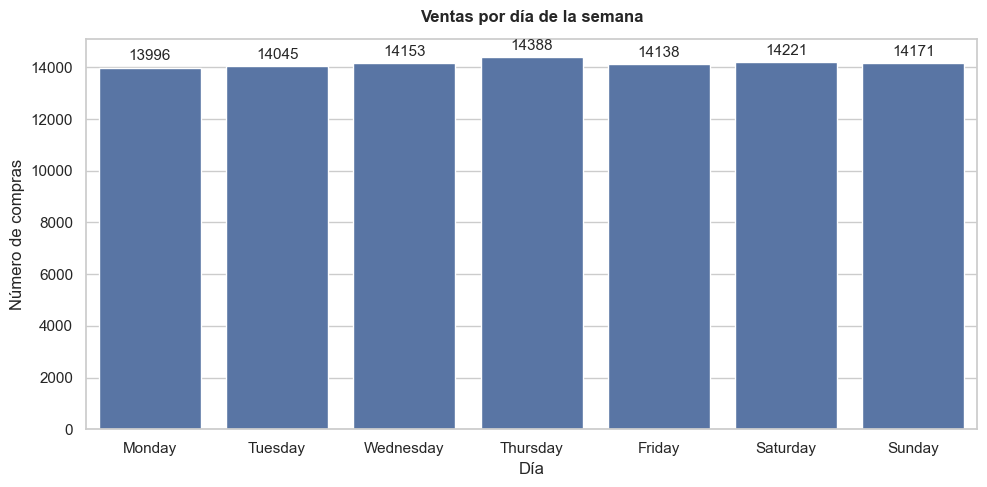

In [18]:
# Gráfico de violín con Seaborn
ax= sns.countplot(
    data=ventas,
    x='dia_semana',
    order=dias_orden,
    color='#4c72b0'
)

# Título y etiquetas
plt.bar_label(ax.containers[0], padding=3)
plt.title("Ventas por día de la semana", weight='bold', pad=12)
plt.xlabel("Día")
plt.ylabel("Número de compras")
plt.tight_layout()

# Mostrar gráfico
plt.show()

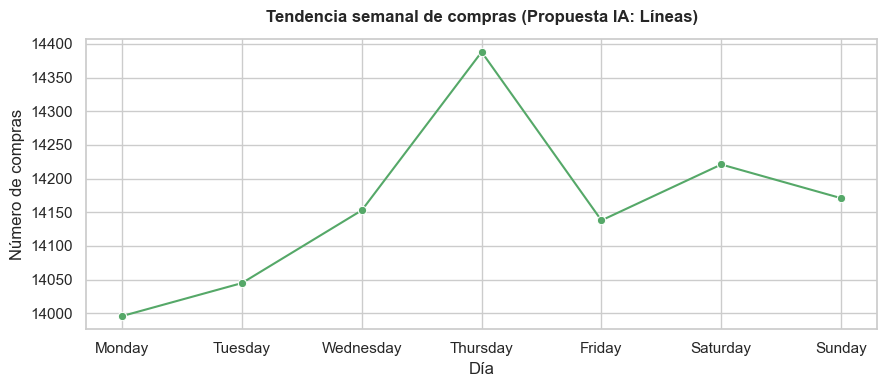

In [19]:
# Alternativa propuesta por la IA: Gráfico de líneas

# 1. Contamos las compras por día
ventas_dia = ventas['dia_semana'].value_counts().reindex(dias_orden).reset_index()
ventas_dia.columns = ['dia_semana', 'num_compras']

# 2. Propuesta IA: Gráfico de líneas
plt.figure(figsize=(9, 4))
sns.lineplot(
    data=ventas_dia,
    x='dia_semana',
    y='num_compras',
    marker='o',
    color='#55a868'
)

plt.title("Tendencia semanal de compras (Propuesta IA: Líneas)", weight='bold', pad=12)
plt.xlabel("Día")
plt.ylabel("Número de compras")
plt.tight_layout()
plt.show()

In [20]:
# 1. Contar el número de ventas por día
ventas_resumen = ventas['dia_semana'].value_counts().reset_index()
ventas_resumen.columns = ['dia_semana', 'num_ventas']

# 2. Identificar el día con más y menos ventas
dia_max = ventas_resumen.loc[ventas_resumen['num_ventas'].idxmax()]
dia_min = ventas_resumen.loc[ventas_resumen['num_ventas'].idxmin()]

# 3. Métricas clave
total_ventas = ventas_resumen['num_ventas'].sum()
diferencia_pct = ((dia_max['num_ventas'] - dia_min['num_ventas']) / dia_min['num_ventas']) * 100

# 4. Salida por pantalla
print(f"Día con más ventas: {dia_max['dia_semana']} ({dia_max['num_ventas']:,} ventas, {(dia_max['num_ventas']/total_ventas)*100:.2f}% del total)")
print(f"Día con menos ventas: {dia_min['dia_semana']} ({dia_min['num_ventas']:,} ventas, {(dia_min['num_ventas']/total_ventas)*100:.2f}% del total)")
print(f"Diferencia entre el día pico y el valle: {diferencia_pct:.2f}%")

Día con más ventas: Thursday (14,388 ventas, 14.52% del total)
Día con menos ventas: Monday (13,996 ventas, 14.12% del total)
Diferencia entre el día pico y el valle: 2.80%


**1. Qué vemos en el gráfico y qué significa para el negocio**

Las compras se distribuyen de forma casi idéntica a lo largo de toda la semana. El día con mayor volumen es el jueves (14.388 ventas, un 14,52% del total) y el más bajo el lunes (13.996 ventas, un 14,12%), con una diferencia mínima de apenas el 2,80% entre ambos.

Para el negocio, esto significa que el comportamiento de compra es completamente homogéneo: no depende de campañas de fin de semana ni sufre caídas de actividad entre semana. Operativamente, el soporte al cliente, la logística y los servidores debería dimensionarse con la misma capacidad de lunes a domingo, sin necesidad de refuerzos especiales para días concretos.

**2. Alternativa de la IA**

La IA propone utilizar un gráfico de líneas para conectar las ventas a lo largo de la semana.

**3. Valoración crítica (Barras vs. Líneas)**

La propuesta de la IA genera confusión. Las líneas se usan para series temporales continuas (meses o años), mientras que los días de la semana son categorías cerradas y cíclicas. Un gráfico de líneas crea la falsa ilusión de una caída o subida continua de tendencia, mientras que las barras reflejan con precisión que el volumen diario es prácticamente constante.

#**NIVEL 1**

###**EJERCICIO 2**
El objetivo es cruzar los datos de las transacciones con el resto de tablas (empresas, usuarios y productos) para entender mejor cómo funciona el negocio en el día a día. Para ello, se analizarán cuatro cuestiones principales:

- **A. Dependencia por países:** comprobar si la mayor parte de los ingresos depende de unos pocos países donde están las empresas vendedoras.

- **B. Estacionalidad en las ventas:** ver si hay meses o épocas del año con más ventas y cómo cambian los resultados de un año a otro.

- **C. Concentración de ventas o actividad:** profundizar en uno de estos dos puntos clave:

   - **Opción A (Productos):** ver qué productos generan más dinero y si sus precios o ventas varían mucho.

   - **Opción B (Usuarios):** calcular cuánto tiempo llevan los clientes sin comprar para detectar si están dejando de usar la plataforma.

- **D. Hábitos de compra por horas:** analizar en qué franjas horarias se vende más y si estos horarios se han mantenido a lo largo de los años.

Para cada punto se resumirán los pasos seguidos con los datos, se mostrará el gráfico correspondiente y se explicará de forma breve y clara qué significan los resultados para el negocio.

###**A. Dependencia por países**

PASOS:

1. Juntar las ventas con la lista de empresas (para saber de qué país es cada venta).

2. Sumar cuánto dinero entra por cada país.

3. Dibujar un gráfico con barras (el dinero de cada país) y una línea roja encima (que va sumando los porcentajes hasta llegar al 100%).

In [21]:
# Cargar el archivo
ruta = "/Users/mar/Downloads/N1-Ex.8__companies.csv"
companies =  pd.read_csv(ruta)

# Solo con las ventas válidas (declined == 0)
ventas = transactions[transactions['declined'] == 0].copy()

# Juntar las dos tablas por el ID de la empresa
df = ventas.merge(companies, left_on='business_id', right_on='company_id')

# Sumar el dinero por país y ordenar de mayor a menor
ventas_pais = df.groupby('country')['amount'].sum().sort_values(ascending=False).reset_index()

# Calcular el porcentaje acumulado (para la línea roja)
total_dinero = ventas_pais['amount'].sum()
ventas_pais['porcentaje'] = (ventas_pais['amount'] / total_dinero) * 100
ventas_pais['acumulado'] = ventas_pais['porcentaje'].cumsum()

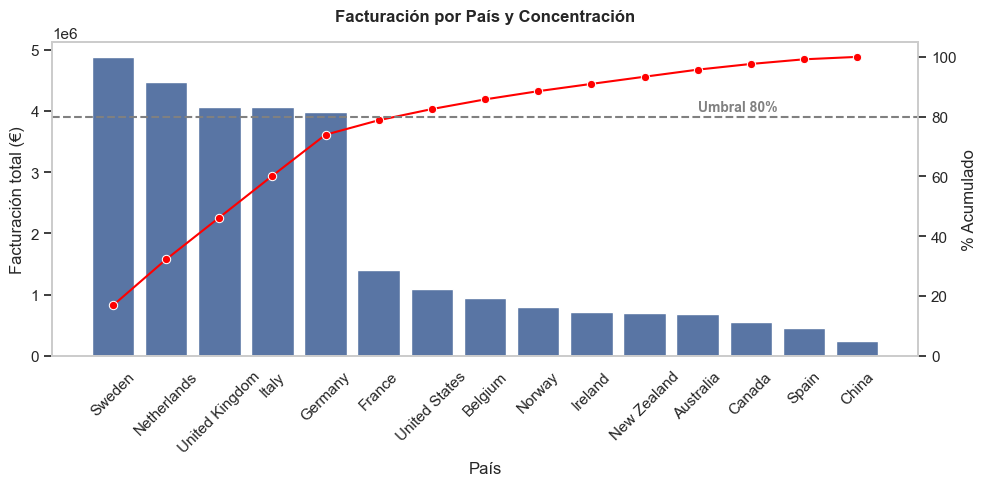

In [22]:
# Crear el Gráfico

fig, ax1 = plt.subplots() #'fig' es el lienzo total y 'ax1' es el eje 1 (gráfico de barras)

# Eje 1 (Izquierda): Barras azules con el dinero de cada país

sns.barplot(
    data=ventas_pais,
    x='country',
    y='amount',
    color='#4c72b0',
    ax=ax1)

## Título y etiquetas

ax1.set_title("Facturación por País y Concentración", weight='bold', pad=15)
ax1.set_xlabel("País")
ax1.set_ylabel("Facturación total (€)")
ax1.tick_params(axis='x', rotation=45)

# Eje 2 (Derecha): Línea roja que va sumando el porcentaje
ax2 = ax1.twinx()
sns.lineplot(
    data=ventas_pais,
    x='country',
    y='acumulado',
    color='red',
    marker='o',
    ax=ax2)

## Titulo y etiquetas
ax2.set_ylabel("% Acumulado")
ax2.set_ylim(0, 105)

# Línea discontinua en el 80% (marca de referencia habitual)
ax2.axhline(80, color='gray', linestyle='--')
ax2.text(11, 82, 'Umbral 80%', color='gray', fontsize=10, fontweight='bold')

# Elimiar cuadrícula
ax1.grid(False)
ax2.grid(False)

plt.tight_layout()
plt.show()


---
###**SOLUCIÓN:**
**¿Dependemos excesivamente de un número reducido de países de compañías vendedoras?**

Sí existe una dependencia de un grupo concreto, ya que 7 de los 15 países generan el 80% de toda la facturación de la empresa, dejando a los 8 restantes con solo un 20%.

Pero dentro de esos 7 países, ninguno tiene un monopolio. El líder es Suecia, seguido de forma muy equilibrada por Países Bajos, Reino Unido, Italia, Alemania y Francia. No dependemos de 1 o 2 mercados, sino de 7 economías sólidas que reparten el peso.

Al estar las ventas distribuidas entre varias economías fuertes, si la actividad cae puntualmente en un país concreto, los demás compensan el impacto y la empresa se mantiene estable.

Los 8 países restantes, que generan solo el 20% conjunto de los ingresos, podría indicar que son mercados secundarios o en fase inicial.

---

 P2P: Si cae el porcentaje si afecta porque no es lo mismo el 5% de 1 millon que de 4 millones. No es lo mismo que cantidades absolutas.

###**B. Estacionalidad en las ventas**

PASOS:

1. Trabajar con las fechas de las transacciones válidas.

2. Extraer el año y el mes.

3. Sumar el dinero (amount) por año y mes.

4. Crear una tabla tipo pivot_table para ver los meses en las filas y los años en las columnas.

5. Hacer un gráfico de líneas para comparar la curva de cada año.

In [23]:
# Asegurar que la columna de fecha sea formato datetime
ventas['timestamp'] = pd.to_datetime(ventas['timestamp'])

# Extraer el año y el mes (número de mes del 1 al 12)
ventas['year'] = ventas['timestamp'].dt.year
ventas['month'] = ventas['timestamp'].dt.month

# Crear la tabla pivot: meses en filas, años en columnas, suma de facturación
pivot_estacionalidad = ventas.pivot_table(
    index='month',
    columns='year',
    values='amount',
    aggfunc='sum'
)

# Mostrar la tabla resultante para revisarla
pivot_estacionalidad

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
month,,,,,,,,,,
1,221978.21,224451.27,222956.21,227411.90,222944.11,231702.95,243339.85,224709.53,228413.66,226393.73
2,245780.13,248112.42,252303.71,245092.09,259807.32,248318.04,257434.31,235427.85,251422.67,249898.07
3,253000.65,246634.37,237621.09,237099.83,276818.21,258872.56,250861.14,271978.12,241711.00,245792.02
4,245597.21,240833.04,251596.72,234246.30,242707.81,244251.90,259770.51,237165.49,241264.06,244769.15
5,248585.36,241306.84,240125.80,244448.97,242550.42,253699.74,239662.08,276262.60,261355.45,254122.62
6,232624.35,230577.43,240337.61,242769.22,241694.85,236410.96,234080.71,260082.37,232254.56,244370.81
7,241252.27,237081.73,240576.35,231261.73,233513.25,240255.64,251450.91,233349.01,238652.72,230031.53
8,233797.97,235600.88,230225.76,228759.89,237070.53,232658.86,237051.75,245198.95,237981.15,236671.63
9,227211.93,241530.84,230606.28,236768.38,232551.83,257964.96,245398.37,254316.72,234226.30,234226.89


P2P: mejorar cambiando los números de los meses por el mes escrito creando un diccionario. Y añadir un mapa de calor con .backgound_gradient y con cmap=coolwarm (la gama de colores que quiero mostrar)

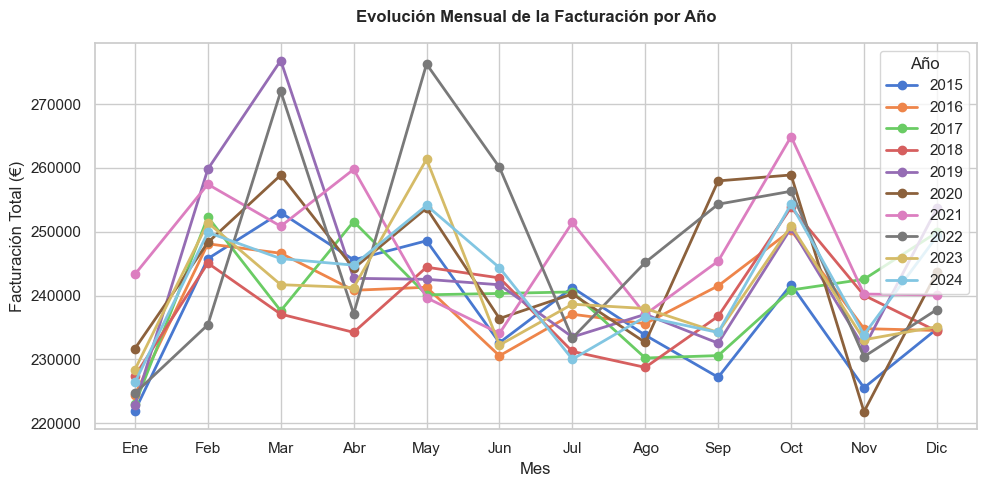

In [24]:
# Gráfico de líneas comparando cada año
fig, ax = plt.subplots()

# Se dibujan las columnas de la tabla pivot (cada año una línea)
pivot_estacionalidad.plot(marker='o', linewidth=2, ax=ax)

# Títulos y etiquetas
plt.title("Evolución Mensual de la Facturación por Año", weight='bold', pad=15)
plt.xlabel("Mes")
plt.ylabel("Facturación Total (€)")
plt.xticks(range(1, 13), ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic'])
plt.legend(title="Año")
plt.tight_layout()

#Mostrar el gráfico
plt.show()

P2P: es más visual y más fácil de interpretar un mapa de calor

---
###**SOLUCIÓN:**
**¿Existe estacionalidad en las ventas?**

Sí, se identifican patrones estacionales consistentes a lo largo de los años.

La facturación experimenta dos picos destacados durante el año: el primero en primavera (especialmente entre marzo y mayo) y el segundo en otoño (marzo y octubre suelen encabezar los ingresos globales). Por contra, los momentos de menor actividad coinciden sistemáticamente con enero (el mes más bajo del año), el periodo estival (julio y agosto) y noviembre.

La compañía experimenta dos momentos de fuerte demanda y tres etapas valle claramente delimitadas. La empresa puede programar promociones o campañas comerciales enfocadas en enero, verano y noviembre para amortiguar esos descensos recurrentes.

---

###**C. Concentración de ventas o actividad - OPCIÓN A**

PASOS:

1. Desanidar los productos.

2. Cruzar tablas.

3. Identificar el Top15.

4. Dibujar el diagrama de caja.

5. Conclusión de negocio

In [25]:
# 1. Cargamos el archivo de productos (ajusta el nombre del archivo si es distinto)
ruta = "/Users/mar/Downloads/N1-Ex.8__products.csv"
productos = pd.read_csv(ruta)

# 1. Creamos una copia para no alterar la tabla original
ventas_prod = ventas.copy()

# 2. Si vienen varios productos juntos separados por comas, los separamos y 'explotamos'
ventas_prod['product_id'] = ventas_prod['product_ids'].astype(str).str.split(',')
ventas_prod = ventas_prod.explode('product_id')

# Limpiamos posibles espacios en blanco y convertimos a número
ventas_prod['product_id'] = ventas_prod['product_id'].str.strip()
ventas_prod['product_id'] = pd.to_numeric(ventas_prod['product_id'], errors='coerce')

# 3. Hacemos el merge uniendo 'product_id' de ventas con 'id' de productos
ventas_productos = ventas_prod.merge(
    productos,
    left_on='product_id',
    right_on='id',
    how='inner'
)

# Vemos que se haya unido bien
ventas_productos[['product_name', 'price', 'amount']].head()


,product_name,price,amount
0,giantsblood maester Karstark,$9.46,176.45
1,Dorne bastard,$114.09,176.45
2,Direwolf Littlefinger,$38.33,176.45
3,duel tourney Lannister,$171.13,206.65
4,Stannis warden,$168.49,548.77


In [26]:
# Sumamos la facturación total por producto
top_productos_totales = (
    ventas_productos.groupby('product_name')['amount']
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

# Obtenemos la lista con los nombres de esos 15 productos
lista_top15 = top_productos_totales.index.tolist()

# Filtramos las ventas para quedarnos solo con esos 15 productos
df_top15 = ventas_productos[ventas_productos['product_name'].isin(lista_top15)]

print(top_productos_totales)

product_name
the duel             3494215.69
Winterfell           3336465.78
skywalker ewok       3176537.71
dooku solo           2998255.28
Karstark warden      2896522.63
Karstark Dorne       2599160.06
Direwolf Stannis     2490861.54
Stannis warden       2165009.58
north                2154669.40
Direwolf             2127336.77
duel warden          2043907.93
duel Direwolf        2020451.20
chewbacca mustafar   1966382.21
Stark Karstark       1847590.42
Lannister            1707691.90
Name: amount, dtype: float64


P2P: Aquí tendría q haber sumado el price no el amount. EL amount es el precio + las tasas + envio - descuento.

/var/folders/tj/bpw2prq53mn9vr9j8vl59hhw0000gq/T/ipykernel_46590/2369359682.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


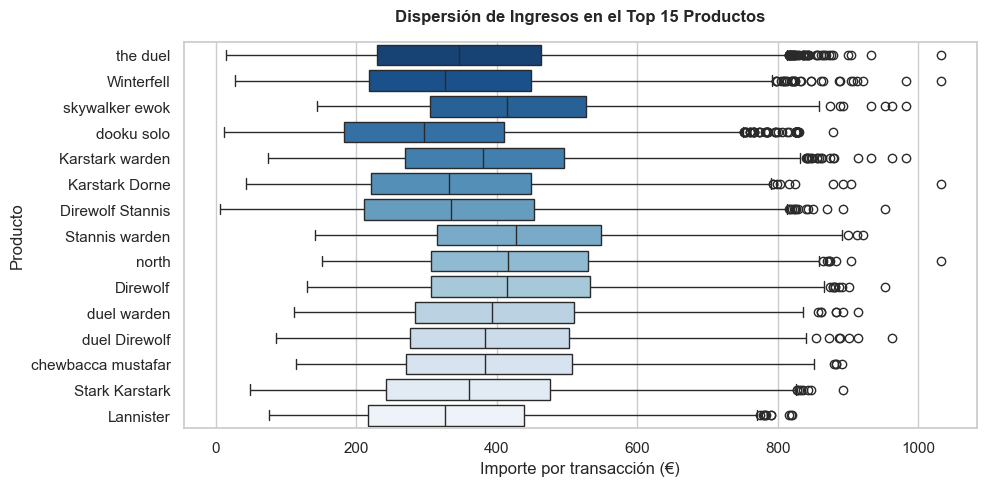

In [27]:
fig, ax = plt.subplots()

# Dibujamos la distribución de los importes de venta de cada uno de los 15 productos
sns.boxplot(
    data=df_top15,
    x='amount',
    y='product_name',
    order=lista_top15,
    palette='Blues_r',
    ax=ax
)

# Títulos y etiquetas
plt.title("Dispersión de Ingresos en el Top 15 Productos", weight='bold', pad=15)
plt.xlabel("Importe por transacción (€)")
plt.ylabel("Producto")

# Elimnar cuadrícula
ax1.grid(False)
ax2.grid(False)

plt.tight_layout()
plt.show()

---
###**SOLUCIÓN:**
**¿Qué productos generan más ingresos y con qué variabilidad??**

El gráfico de cajas muestra que el comportamiento de compra es muy homogéneo en todos los productos del Top 15.

Las cajas tienen prácticamente el mismo ancho, lo que significa que el nivel de variabilidad es muy similar entre ellos: en casi todos los artículos, la mayoría de ventas se concentra de forma regular entre los 200 € y los 550 €. La única diferencia leve es que artículos como *the duel* o *Winterfell* tienen su venta típica (mediana) ligeramente más baja (alrededor de 350 €), por lo que alcanzan su liderazgo en facturación gracias a un mayor volumen de compras. Además, todos los productos comparten compras puntuales elevadas que superan los 800 €.

Para el negocio, esta uniformidad es positiva: al tener un patrón de precios tan estable y predecible en todo el catálogo líder, la empresa puede aplicar políticas de stock y promociones similares sin asumir riesgos imprevistos de dispersión.

---

###**D. Hábito de compras por horas**

PASOS:

1. Extraer el día de la semana y la hora.

2. Crear una tabla cruzada.

3. Ordenar los días cronológicamnente.

4. Dibujar el Mapa de Calor.

5. Conclusión de negocio

In [28]:
## 1. Agrupamos las horas en 4 franjas sencillas
def asignar_franja(hora):
    if 0 <= hora < 6:
        return 'Madrugada (00-06h)'
    elif 6 <= hora < 12:
        return 'Mañana (06-12h)'
    elif 12 <= hora < 18:
        return 'Tarde (12-18h)'
    else:
        return 'Noche (18-24h)'

ventas['franja_horaria'] = ventas['hour'].apply(asignar_franja)

# 2. Creamos la tabla pivot: Franjas en filas y Años en columnas
orden_franjas = ['Madrugada (00-06h)', 'Mañana (06-12h)', 'Tarde (12-18h)', 'Noche (18-24h)']
habito_anos = ventas.pivot_table(
    index='franja_horaria',
    columns='year',
    values='id',
    aggfunc='count'
).reindex(orden_franjas)

# 3. Revisar tabla
habito_anos

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
franja_horaria,,,,,,,,,,
Madrugada (00-06h),2431,2454,2425,2496,2437,2591,2569,2548,2492,2438
Mañana (06-12h),2443,2461,2456,2410,2536,2445,2555,2431,2528,2473
Tarde (12-18h),2425,2481,2531,2487,2526,2453,2569,2497,2448,2502
Noche (18-24h),2478,2374,2421,2430,2429,2520,2505,2539,2434,2444


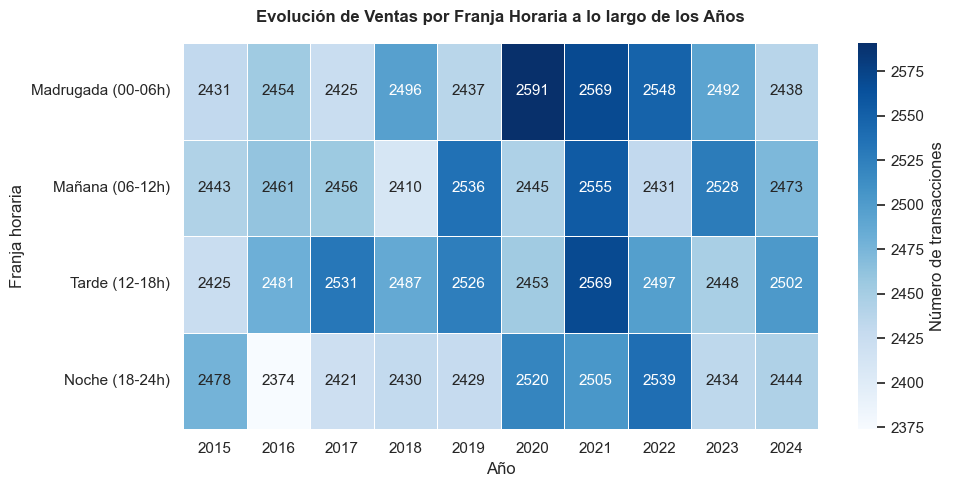

In [29]:
# Crear lienzo (tamaño predeterminado inicial 10x5)
fig, ax = plt.subplots()

# Dibujar mapa de calor (los colores intensos indican más compras)
sns.heatmap(
    habito_anos,
    annot=True, # Para que nos muestre los datos escritos
    fmt='d', # Formato de números enteros sin decimales
    cmap='Blues',
    cbar_kws={'label': 'Número de transacciones'},
    linewidths=0.5,
    ax=ax
)

#Títulos y etiquetas
plt.title("Evolución de Ventas por Franja Horaria a lo largo de los Años", weight='bold', pad=15)
plt.xlabel("Año")
plt.ylabel("Franja horaria")
plt.tight_layout()

# Mostrar gráfico
plt.show()

---
###**SOLUCIÓN:**
**¿Cómo varía la actividad de venta por franjas horarias a lo largo de los años?**

La actividad es sumamente estable y no presenta cambios marcados entre franjas ni a lo largo del tiempo.

En todos los años analizados, las 4 franjas horarias registran prácticamente el mismo volumen de compras, situándose en un rango muy estrecho entre 2.370 y 2.590 operaciones cada una. Ninguna franja (mañana, tarde, noche o madrugada) destaca claramente sobre las demás, lo que confirma visualmente un mapa de color con tonos muy homogéneos.

Al no existir una caída de ventas por la noche, el negocio funciona de forma continua (24/7). Para la empresa, eso facilita una planificación regular del personal y de los recursos sin necesidad de reforzar turnos concretos, pero exige mantener la plataforma siempre activa, ya que una parada técnica de madrugada afectaría a un volumen real de compras similar al resto del día.

---

#**NIVEL 2**

###**EJERCICIO 1**

**Análisis de productos y captación de clientes**

El objetivo de este análisis es evaluar la salud del catálogo comercial y entender cómo los productos contribuyen al crecimiento de la empresa. En concreto, se busca responder a una pregunta clave: ¿los productos más vendidos ayudan a atraer nuevos clientes, o el negocio depende casi siempre de los mismos usuarios recurrentes? Para averiguarlo, se estudiarán cuatro aspectos principales:

**A. Ingresos y estabilidad:** cuánto dinero genera cada producto y si sus ventas son regulares o varían mucho en el tiempo.

**B. Capacidad de captación:** qué productos funcionan como puerta de entrada para clientes que compran por primera vez frente a los que compran de forma habitual.

**C. Clasificación del catálogo:** agrupar los productos en perfiles claros según su comportamiento en el negocio:

  - *Captadores:* atraen a muchos clientes nuevos.

  - *Recurrentes:* generan grandes ingresos gracias a clientes habituales, pero atraen a pocos nuevos.

  - *Emergentes:* facturan poco todavía, pero tienen buena tracción de nuevos usuarios.

  - *Estancados:* tienen pocas ventas y casi no atraen a nadie nuevo.

**D. Relación visual de las métricas:** comparar de forma gráfica los ingresos, el volumen de nuevos usuarios y la estabilidad de cada producto para identificar riesgos comerciales.

El análisis incluirá el procesamiento de los datos, la visualización final de los productos y una reflexión sobre el riesgo que supone para el negocio depender de pocos productos o no atraer nuevos clientes.

---

**PASO 1**

**Filtrar las transacciones válidas y ordenar por fecha**

Se toma `transactions`, se descartan las compras rechazadas (declined == 0), se conviete la columna de fecha en formato datetime y se ordena cronológicamente.

In [30]:
ventas_ok = transactions[transactions["declined"] == 0].copy()
ventas_ok["timestamp"] = pd.to_datetime(ventas_ok["timestamp"])
ventas_ok = ventas_ok.sort_values("timestamp")

**PASO 2**

**Identificar si la compra corresponde a un nuevo cliente**

Se comprueba si el `user_id` ya había aparecido antes en las transacciones previas. La primera vez que aparece da `True`(nuevo). En las siguientes da `False`(recurrente).

In [31]:
ventas_ok["es_nuevo"] = ~ventas_ok.duplicated("user_id")

**PASO 3**

**Desglosar los productos por fila y cruzar con el catálogo**

Se separan las listas de prodcutos en filas individuales con `explode`. Se limpian los identificadores numéricos y se añada la información del catálogo de `productos` mediante un cruce con `merge`.

In [32]:
ventas_ok["product_id"] = ventas_ok["product_ids"].astype(str).str.split(",")
ventas_limpio = ventas_ok.explode("product_id")
ventas_limpio["product_id"] = ventas_limpio["product_id"].astype(int)

df = ventas_limpio.merge(productos, left_on="product_id", right_on="id", how="inner")

**PASO 4**

**Agrupar y calcular las métrica por cad producto**

Se calcul el total facturado (`sum`), la cantidad de nuevos clientes captados, también con `sum`y la dispersión en los importes de venta para cada producto con `std`.

In [33]:
# 1. Agrupamos por producto y sumamos ingresos y clientes nuevos
resumen = (df.groupby("product_name")[["amount","es_nuevo"]].sum().reset_index())

#2. Renonbramos
resumen.columns = ["product_name", "ingresos", "nuevos"]

**PASO 5**

**Clasificar los productos según las medianas**

Calcular la mediana de ingresos y de nuevos clientes para categorizar cada artículo en uno de los cuatro cuadrantes: Captador, Recurrente, Emergente o Estancado.

In [34]:
#1. Sacamos los puntos de corte (la mediana de cada métrica)
med_ing = resumen["ingresos"].median()
med_nuevos = resumen["nuevos"].median()

#2. Creamos la regla con if/else
def clasificar(fila):
  if fila["ingresos"] >= med_ing and fila["nuevos"] >= med_nuevos:
    return "Captador"
  elif fila["ingresos"] >= med_ing and fila["nuevos"] < med_nuevos:
    return "Recurrente"
  elif fila["ingresos"] < med_ing and fila["nuevos"] >= med_nuevos:
    return "Emergente"
  else:
    return "Estancado"

#3. La aplicamos a toda la tabla
resumen["tipo"] = resumen.apply(clasificar, axis=1)

**PASO 6**

**Generar el gráfico de dispersión**

Se construte la visualización con los ejes de ingresos y nuevos clientes, traza las líneas de división de las medianas.

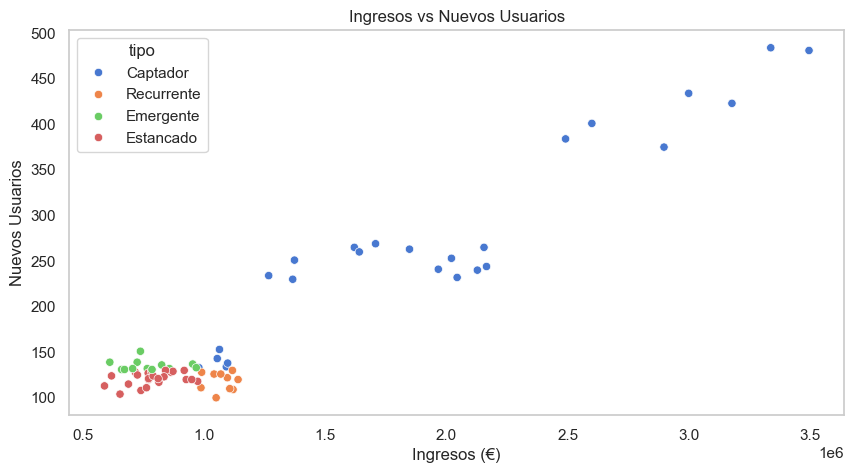

In [35]:
# 1. Dibujamos los puntos: X = ingresos, Y = nuevos, Color = tipo
sns.scatterplot(
    data=resumen,
    x="ingresos",
    y="nuevos",
    hue="tipo"
  )

# 2. Ponemos títulos claros
plt.title("Ingresos vs Nuevos Usuarios")
plt.xlabel("Ingresos (€)")
plt.ylabel("Nuevos Usuarios")

# 3. Quitamos la cuadrícula y muestras
plt.grid(False)
plt.show()

P2P: comporbar los valores azules por qué están tan extremos y ver la posiblidad de cambiar la escala del eje x que ahora es 1e6

**Interpretación**

**AZUL: Las estrellas del negocio**

*¿QUÉ PASA?* Dan mucho dinero y traen a la gran mayoría de clientes nuevos.

*QUÉ HACER? Cuidarlos al máximo. Que nunca falte stock de estos productos y gastar dinero en ponerles anucios, porque son la puerta de entrada a la tienda.

**NARANJA: Los fieles**

*¿QUÉ PASA?* Dan buen dinero, pero no traen gente nueva. Casi siempre los que los compran suelen ser personas que ya los conocen.

*¿QUÉ HACER?* Mantener contentos a los clientes que los compran. Quizás con descuentos por emails, tarqjetas de puntos o suscripcines.

**VERDE: Las promesas**

*¿QUÉ PASA?* LLaman la atención de compradores nuevos, pero todavía dan poco dinero. A veces, puede ser porque son cosas baratas que se ponen para probar la aceptación de los clientes.

*¿QUÉ HACER? Una idea sería intentar venderles algo más junto con este producto. Hacer como un pack. Así se podría ganar más dinero con cada compra.

**ROJO: Los que no funcionan**

*¿QUÉ PASA?* No dan casi dinero y no atraen a nadie nuevo.

*¿QUÉ HACER? Rebajarlos o ponerlos en una sección de OUTLET, para así quitárselos de encima del almacén y dejar de venderlos.

---
###**SOLUCIÓN:**
Los productos que más se venden atraen a clientes nuevos. Por lo que, el negocio no vive solo de los clientes de siempre, sino que los productos estrella hacen que entre gente nueva todos los días.

Pero hay que tener en cuenta que la mayoría de los productos están amontonados abajo, ganando muy poco. Casi todo el éxito de la tienda recae en pocos productos que están más hacia arriba a la derecha. El peligro de esto, es que si alguno de esos pocos productos estrella se deja de poner de moda, se agota o falla el proveedor, las ventas y la llegada de nuevos clientes se desplomarían a la vez.

---

#**NIVEL 2**

###**EJERCICIO 2**

**Análisis geográfico y oportunidades de expansión**

El objetivo de este análisis es estudiar cómo interactúan los países de las empresas vendedoras con los países de residencia de los clientes para entender las rutas de compra. En concreto, se busca responder a una cuestión estratégica clave: ¿el negocio funciona principalmente en mercados locales (mismo país entre comprador y vendedor) o existe una demanda internacional que justifique abrir nuevas empresas en otros países? Para valorarlo, se analizarán cuatro aspectos principales:

**A. Peso del comercio local frente al internacional:** medir qué porcentaje de las ventas y de la facturación total se realiza dentro del mismo país y cuánto cruza fronteras.

**B. Comportamiento por país del cliente:** analizar desde dónde compran los usuarios, qué parte de su gasto se queda en empresas locales y cuánto dinero destinan a compras internacionales.

**C. Dependencia y origen de ingresos por país vendedor:** evaluar en cada país de las empresas qué proporción de sus ventas proviene de clientes nacionales y cuánto procede del extranjero.

**D. Oportunidades estratégicas de expansión:** identificar mercados donde existe una alta demanda de clientes pero poca oferta de empresas locales, valorando si crear presencia en esos países ayudaría a reducir costes y vender más.

El estudio se apoyará en una visualización de los flujos de compra y concluirá con recomendaciones prácticas sobre en qué países conviene expandir la red de empresas y qué riesgos de concentración geográfica conviene vigilar.

In [36]:
#Importamos librerías
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

**PASO 1**

**Cargar y unificar usuarios europeos y americanos**

Se cargan los dos archivos CSV de usuarios y se unen uno debajo del otro en una misma tabla llamada `users`.

In [37]:
# 1. Cargamos usuarios europeos y americanos
eu_users = pd.read_csv("/Users/mar/Downloads/N1-Ex.8__european_users.csv")
am_users = pd.read_csv("/Users/mar/Downloads/N1-Ex.8__american_users.csv")

# 2. Los unimos en una única tabla 'users'
users = pd.concat([eu_users, am_users], ignore_index=True)

**PASO 2**

**Juntar las tablas necesarias**

Se filtran las trasacciones buenas, que no han sido rechazadas y se usa `.merge()` dos veces. Primero para saber de qué país es el cliente (`users`) y luego para saber de qué país es la empresa que vende (`companies`).

In [38]:
# 1. Quitamos ventas rechazadas
ventas_ok = transactions[transactions["declined"] == 0].copy()

# 2. Añadimos el país del usuario
ventas_usuario = ventas_ok.merge(
    users[['id', 'country']],
    left_on='user_id',
    right_on='id'
).rename(columns={'country': 'pais_usuario'})

# 3. Añadimos el país de la empresa
ventas_empresa = ventas_usuario.merge(
    companies[['company_id', 'country']],
    left_on='business_id',
    right_on='company_id'
).rename(columns={'country': 'pais_empresa'})

# Renombramos DataFrame
df = ventas_empresa


**PASO 3**

**Crear la columna de "compra local**

Se comprueba si el país de residencia del comprador coincide con el país donde está registrada la empresa.

In [39]:
df["compra_local"] = df["pais_usuario"] == df["pais_empresa"]

**PASO 4**

**Comportamiento global**

Se calcula qué proporción de transacciones y de volumen de dinero se realiza dentro del mismo país frente al extranjero.

In [40]:
# Contamos cuántas compras fueron locales y cuántas al extranjero
porcentaje_compras_locales = df["compra_local"].mean() * 100
porcentaje_compras_fuera = 100 - porcentaje_compras_locales

# Calculamos el dinero que representan
dinero_local = df[df["compra_local"] == True]["amount"].sum()
dinero_total = df["amount"].sum()
porcentaje_dinero_local = (dinero_local / dinero_total) * 100
porcentaje_dinero_fuera = 100 - porcentaje_dinero_local

print(f"Compras locales: {porcentaje_compras_locales:.1f}%")
print(f"Compras al extranjero: {porcentaje_compras_fuera:.1f}%")
print(f"Dinero en compras locales: {porcentaje_dinero_local:.1f}%")
print(f"Dinero al extranjero: {porcentaje_dinero_fuera:.1f}%")

Compras locales: 11.9%
Compras al extranjero: 88.1%
Dinero en compras locales: 11.9%
Dinero al extranjero: 88.1%


**PASO 5**

**Análisis por país del cliente**

Se agrupa por país de usuario para ver cuánto dinero gasta la gente de cada país y qué porcentaje de sus compras las hacen a empresas de fuera

In [41]:
# 1. Agrupamos por país de usuario
resumen_usuarios = (
    df.groupby("pais_usuario")
    .agg(
        dinero_gastado=("amount", "sum"),
        total_compras=("compra_local", "count"),
        compras_en_casa=("compra_local", "sum"),
    )
    .reset_index()
)

# 2. Calculamos los porcentajes
resumen_usuarios["pct_local"] = (
    resumen_usuarios["compras_en_casa"] / resumen_usuarios["total_compras"]
) * 100

resumen_usuarios["pct_extranjero"] = 100 - resumen_usuarios["pct_local"]

**PASO 6**

**Análisis por páis de la empresa**

Se calcula para cada país vendedor cuánto dinero ingresa gracias a compradores locales y cuánto gracias a compradores que viven fuera.

In [42]:
# Filtramos y sumamos el dinero según sea local o internacional
ventas_locales = (
    df[df["compra_local"] == True]
    .groupby("pais_empresa")["amount"]
    .sum()
    .rename("ingresos_locales")
)
ventas_fuera = (
    df[df["compra_local"] == False]
    .groupby("pais_empresa")["amount"]
    .sum()
    .rename("ingresos_extranjeros")
)

# Unimos las dos métricas
resumen_empresas = (
    pd.concat([ventas_locales, ventas_fuera], axis=1).fillna(0).reset_index()
)


**PASO 7**

**Visualización gráfica**

Se utiliza un gráfico de barras horizontales

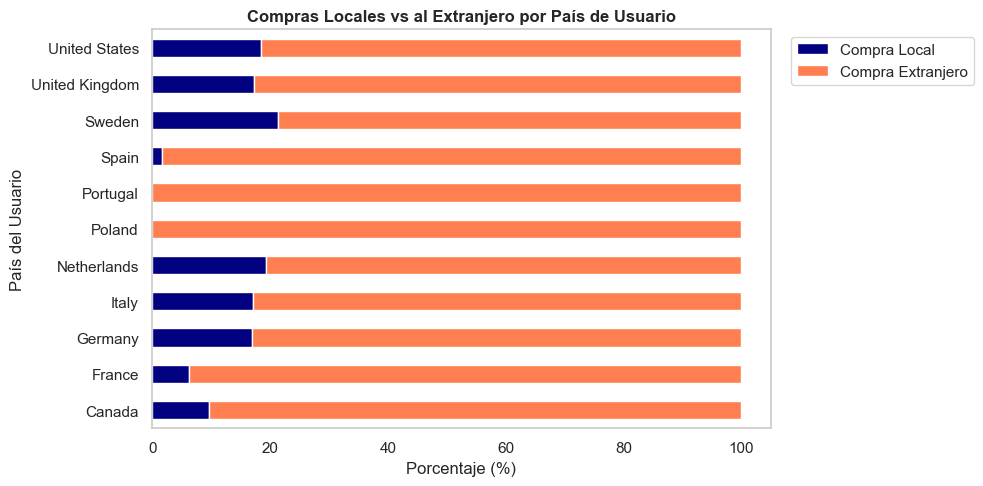

In [43]:
# 1. Ponemos el nombre del país en cada barra
grafico = resumen_usuarios.set_index("pais_usuario")[
    ["pct_local", "pct_extranjero"]
]

# 2. Dibujamos las barras horizontales
grafico.plot(
    kind="barh",
    stacked=True,
    color=["navy", "coral"]
)

# 3. Títulos y etiquetas limpias
plt.title(
    "Compras Locales vs al Extranjero por País de Usuario",
    weight="bold",
)
plt.xlabel("Porcentaje (%)")
plt.ylabel("País del Usuario")
plt.legend(["Compra Local", "Compra Extranjero"], bbox_to_anchor=(1.02, 1))
plt.grid(False)
plt.tight_layout()
plt.show()

###**SOLUCIÓN:**

**1. ¿En qué países valdría la pena abrir más compañías locales?**

Valdría la pena en Polonia, Portugal, España y Francia. En el gráfico se ve que en estos lugares casi toda la barra es naranja, lo que significa que la gente compra prácticamente todo fuera de su país. si se abrieran empresas locales allí, los clientes podrían comprar directamente en su país y ese dinero se quedaría en casa.

**2. ¿Hay países con demanda pero poca oferta local?**

Sí, totalmente. Hay países donde los usarios quieren comprar (hay demanda) y gastan dinero pero no tienen tiendas en su propio país donde hacerlo (falta oferta). El ejemplo más claro son Polonia y Portugal, que no tienen ni una sola compra local, la barra azul es 0%.

**3. ¿El negocio depende demasiado de compañías de un solo país?**

Sí, hay una dependencia muy grande. Al ver que en casi todos los países la barra naranja supera el 80%, sabemos que casi todo el mundo compra fuera de sus fronteras. Eso significa que la inmensa mayoría de las ventas están concentradas en empresas de solos dos o tres países vendedores principales. Esto es un riesgo porque si en esos países vendedores subieran los impuestos o cambiaras las leyes de envíos, todo el negocio sufriría un impacto.

**4. ¿Abrir compañías locales reduciría fricción o mejoraría la conversión?**

Sí, ayudaría muchísimo a vender más. Cuando una persona compra a una empresa de otro país, muchas veces duda o cancela por miedo a que haya problemas con el envío. En cambio, cuando el cliente ve que la tienda es de su propio país, siente más confianza, compra sin darle tantas vueltas y se cierran muchas más ventas.